# Métriques d'évaluation : résumé automatique, question-réponse, génération de texte
Master Data & IA, INPT. **Les exemples de ce notebook sont les mêmes que ceux des slides.**

Pour chaque métrique : *ce qu'elle mesure → formule → calcul pas à pas → score final → interprétation → avantages et limites.*
Tous les chiffres sont calculés par le code (rien n'est tapé à la main).

| Tâche | Métriques implémentées à la main |
|---|---|
| A. Résumé automatique | ROUGE-1, ROUGE-2, ROUGE-L, BERTScore (P, R, F1) |
| B. Question-réponse | Exact Match, précision, rappel, F1 par tokens |
| C. Génération de texte | Perplexité, Distinct-1, Distinct-2 (+ évaluation humaine, expliquée) |

**Plan de la démo (1 min 40).** Le notebook est déjà exécuté : on fait défiler les sorties.
- **A (0:35)** : le calcul pas à pas de ROUGE pour le candidat 1, puis le tableau ROUGE / BERTScore et le graphique.
- **B (0:30)** : le calcul de la question 2, puis le tableau des 6 exemples.
- **C (0:35)** : la perplexité de « the model is good », le calcul de Distinct-n, puis le tableau final A / B / C.

In [1]:
# Colab : torch est déjà installé. Ces bibliothèques servent seulement à vérifier notre code
# (rouge-score), à charger les vecteurs de mots (gensim) et à lancer le vrai BERTScore (bert-score).
!pip install -q rouge-score bert-score transformers gensim

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import re, math, collections
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rouge_score import rouge_scorer

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
IVORY, SAND, CHAR, TAUPE = "#F7F3EA", "#D6C9B0", "#2B2B2B", "#8C7B6B"     # même palette que les slides
plt.rcParams.update({"figure.facecolor": IVORY, "axes.facecolor": IVORY, "axes.edgecolor": CHAR,
                     "text.color": CHAR, "axes.labelcolor": CHAR, "xtick.color": CHAR, "ytick.color": CHAR,
                     "axes.spines.top": False, "axes.spines.right": False})

def tokenize(text):
    # minuscules, on garde seulement lettres et chiffres (même convention que la bibliothèque ROUGE)
    return re.findall(r"[a-z0-9]+", text.lower())

def prf(overlap, n_pred, n_ref):
    # Précision = recouvrement / taille de la prédiction ; Rappel = recouvrement / taille de la référence ; F1 = moyenne harmonique
    p = overlap / n_pred if n_pred else 0.0
    r = overlap / n_ref if n_ref else 0.0
    f = 2 * p * r / (p + r) if (p + r) else 0.0
    return p, r, f

## Section A. Résumé automatique
**Question posée :** le résumé généré contient-il le même *contenu* qu'un résumé de référence écrit par un humain ?
**Pourquoi plusieurs métriques ?** un seul nombre ne dit pas si un résumé a les *mêmes mots* (lexical) ou le *même sens* (sémantique).

**Notre exemple (le même que les slides 2 à 5).** Une référence, deux candidats :
- Le candidat 1 dit la même chose avec d'autres mots (une paraphrase).
- Le candidat 2 reprend presque tous les mots mais change le sens (*cut* au lieu de *raised*, *unemployment* au lieu de *inflation*).

In [3]:
reference = "The central bank raised interest rates to fight rising inflation."
candidates = {
    "Candidat 1 (paraphrase)":    "Inflation pressure pushed the central bank to increase its borrowing costs.",
    "Candidat 2 (sens erroné)": "The central bank cut interest rates to fight rising unemployment.",
}
print("RÉFÉRENCE :", reference, "->", len(tokenize(reference)), "mots")
for k, v in candidates.items():
    print(f"{k}: {v} -> {len(tokenize(v))} mots")

RÉFÉRENCE : The central bank raised interest rates to fight rising inflation. -> 10 mots
Candidat 1 (paraphrase): Inflation pressure pushed the central bank to increase its borrowing costs. -> 11 mots
Candidat 2 (sens erroné): The central bank cut interest rates to fight rising unemployment. -> 10 mots


### A.1 ROUGE-N et ROUGE-L (recouvrement lexical)
| Élément | ROUGE-N | ROUGE-L |
|---|---|---|
| Mesure | combien de n-grammes (groupes de N mots) de la référence se retrouvent dans le candidat | la plus longue sous-séquence commune (LCS) : la plus longue suite de mots présente dans les deux textes **dans le même ordre** (trous permis) |
| Précision | recouvrement / nombre de n-grammes du **candidat** | LCS / nombre de mots du **candidat** |
| Rappel | recouvrement / nombre de n-grammes de la **référence** | LCS / nombre de mots de la **référence** |
| F1 | 2·P·R / (P + R) | idem |

*recouvrement* = nombre de n-grammes communs, **plafonnés** : un n-gramme compte au plus autant de fois qu'il apparaît dans les deux textes (intersection de `Counter`).
**Lecture d'un score :** 0 = aucun mot commun, 1 = n-grammes identiques. Rappel élevé = le résumé couvre la référence ; précision élevée = peu de contenu superflu.
**Pourquoi c'est nécessaire :** c'est la façon standard, peu coûteuse, de comparer des résumés à une référence.
**Avantage :** rapide, transparent, sans modèle. **Limite :** il ne voit que les mots de surface : une paraphrase est pénalisée et un résumé faux avec les bons mots est récompensé.

In [4]:
def ngrams(tokens, n):
    return [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]

def rouge_n(ref, cand, n):
    r_grams, c_grams = ngrams(tokenize(ref), n), ngrams(tokenize(cand), n)
    shared = Counter(r_grams) & Counter(c_grams)            # intersection (comptes plafonnés)
    overlap = sum(shared.values())
    p, r, f = prf(overlap, len(c_grams), len(r_grams))
    return dict(shared=[" ".join(g) for g in shared], overlap=overlap, n_cand=len(c_grams), n_ref=len(r_grams), P=p, R=r, F1=f)

def lcs(a, b):
    # table de programmation dynamique : L[i][j] = longueur de la LCS de a[:i] et b[:j]
    L = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            L[i][j] = L[i-1][j-1] + 1 if a[i-1] == b[j-1] else max(L[i-1][j], L[i][j-1])
    seq, i, j = [], len(a), len(b)                          # remontée pour retrouver la séquence elle-même
    while i and j:
        if a[i-1] == b[j-1]: seq.append(a[i-1]); i -= 1; j -= 1
        elif L[i-1][j] >= L[i][j-1]: i -= 1
        else: j -= 1
    return L[-1][-1], seq[::-1]

def rouge_l(ref, cand):
    r, c = tokenize(ref), tokenize(cand)
    length, seq = lcs(r, c)
    p, rec, f = prf(length, len(c), len(r))
    return dict(shared=seq, overlap=length, n_cand=len(c), n_ref=len(r), P=p, R=rec, F1=f)

**Calcul pas à pas pour le candidat 1** (la paraphrase).

In [5]:
cand = candidates["Candidat 1 (paraphrase)"]
for name, d in [("ROUGE-1", rouge_n(reference, cand, 1)), ("ROUGE-2", rouge_n(reference, cand, 2)), ("ROUGE-L", rouge_l(reference, cand))]:
    print(f"--- {name} ---")
    print("unités communes :", d["shared"])
    print(f"recouvrement = {d['overlap']}   |candidat| = {d['n_cand']}   |référence| = {d['n_ref']}")
    print(f"Précision = {d['overlap']}/{d['n_cand']} = {d['P']:.3f}")
    print(f"Rappel    = {d['overlap']}/{d['n_ref']} = {d['R']:.3f}")
    print(f"F1        = 2*{d['P']:.3f}*{d['R']:.3f} / ({d['P']:.3f}+{d['R']:.3f}) = {d['F1']:.3f}\n")

--- ROUGE-1 ---
unités communes : ['the', 'central', 'bank', 'to', 'inflation']
recouvrement = 5   |candidat| = 11   |référence| = 10
Précision = 5/11 = 0.455
Rappel    = 5/10 = 0.500
F1        = 2*0.455*0.500 / (0.455+0.500) = 0.476

--- ROUGE-2 ---
unités communes : ['the central', 'central bank']
recouvrement = 2   |candidat| = 10   |référence| = 9
Précision = 2/10 = 0.200
Rappel    = 2/9 = 0.222
F1        = 2*0.200*0.222 / (0.200+0.222) = 0.211

--- ROUGE-L ---
unités communes : ['the', 'central', 'bank', 'to']
recouvrement = 4   |candidat| = 11   |référence| = 10
Précision = 4/11 = 0.364
Rappel    = 4/10 = 0.400
F1        = 2*0.364*0.400 / (0.364+0.400) = 0.381



**Scores finaux pour les deux candidats**, avec une vérification contre la bibliothèque officielle `rouge-score` (notre F1 manuel doit être identique).

In [6]:
scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=False)
rows = []
for name, cand in candidates.items():
    mine = {"ROUGE-1": rouge_n(reference, cand, 1), "ROUGE-2": rouge_n(reference, cand, 2), "ROUGE-L": rouge_l(reference, cand)}
    lib = scorer.score(reference, cand)
    for key, libkey in [("ROUGE-1", "rouge1"), ("ROUGE-2", "rouge2"), ("ROUGE-L", "rougeL")]:
        assert abs(mine[key]["F1"] - lib[libkey].fmeasure) < 1e-9, "manual and library scores differ!"
    row = {"Summary": name}
    for key, d in mine.items():
        row[f"{key} P"], row[f"{key} R"], row[f"{key} F1"] = d["P"], d["R"], d["F1"]
    rows.append(row)
rouge_df = pd.DataFrame(rows).set_index("Summary")
print("Implémentation manuelle = bibliothèque officielle sur les 6 valeurs de F1.")
rouge_df

Implémentation manuelle = bibliothèque officielle sur les 6 valeurs de F1.


,ROUGE-1 P,ROUGE-1 R,ROUGE-1 F1,ROUGE-2 P,ROUGE-2 R,ROUGE-2 F1,ROUGE-L P,ROUGE-L R,ROUGE-L F1
Summary,,,,,,,,,
Candidat 1 (paraphrase),0.455,0.5,0.476,0.200,0.222,0.211,0.364,0.4,0.381
Candidat 2 (sens erroné),0.800,0.8,0.800,0.667,0.667,0.667,0.800,0.8,0.800


**Interprétation.**
- Le candidat 2 (sens erroné) obtient **ROUGE-1 F1 = 0.80** et le candidat 1 (bonne paraphrase) seulement **0.48** : ROUGE récompense les mots copiés, pas le sens.
- ROUGE-2 chute plus vite que ROUGE-1 pour la paraphrase (0.21 contre 0.48) : les *paires* de mots sont plus fragiles que les mots seuls.
- Pour le candidat 1, ROUGE-L (0.38) est inférieur à ROUGE-1 car les mots communs (*inflation* contre *the central bank to*) ne sont pas dans le même ordre.

### A.2 BERTScore (similarité sémantique)
| Élément | Description |
|---|---|
| Mesure | la proximité du *sens* de chaque mot, en comparant des vecteurs (embeddings) au lieu de chaînes exactes |
| Formule | **R = (1/\|réf\|) Σ<sub>r∈réf</sub> max<sub>c∈cand</sub> cos(r, c)**,  **P = (1/\|cand\|) Σ<sub>c∈cand</sub> max<sub>r∈réf</sub> cos(c, r)**,  **F1 = 2PR/(P+R)** |
| Composants | `cos(x, y) = x·y / (‖x‖‖y‖)` est la similarité cosinus de deux vecteurs (1 = même direction). `max` = *appariement glouton* : chaque mot prend son meilleur correspondant dans l'autre texte. Le rappel moyenne sur les mots de la référence, la précision sur ceux du candidat. |
| Lecture d'un score | plus proche de 1 = sens plus proche. Les valeurs brutes sont comprimées dans une bande haute : les auteurs proposent un *recalage par la ligne de base*. |
| Avantage | associe synonymes et paraphrases (*raised* ~ *increase*). |
| Limite | exige un modèle pré-entraîné ; scores difficiles à lire en absolu ; il mesure la similarité, pas la vérité : il peut rater des erreurs factuelles. |

**Important (comme sur les slides 4 et 5).** Ici, GloVe sert uniquement à illustrer la similarité par embeddings. Le vrai BERTScore utilise des représentations *contextuelles* de BERT/RoBERTa, qu'on ne peut pas calculer à la main.
Pour montrer chaque étape, l'exemple ci-dessous applique **exactement le même algorithme** (appariement glouton par cosinus, P, R, F1) à des **vecteurs de mots GloVe** (vrais vecteurs, mais non contextuels).
La cellule suivante lance ensuite le vrai BERTScore en complément (elle demande un téléchargement de modèle).

In [7]:
# Vecteurs de mots GloVe pré-entraînés (100 dimensions, environ 128 Mo ; téléchargés une seule fois)
import gensim.downloader as api
kv = api.load("glove-wiki-gigaword-100")
print("taille des vecteurs :", kv.vector_size, "| vocabulaire :", len(kv.key_to_index))

[==================================================] 100.0% 128.1/128.1MB downloaded
taille des vecteurs : 100 | vocabulaire : 400000


In [8]:
def cosine(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

def bertscore_greedy(ref, cand, kv):
    r, c = tokenize(ref), tokenize(cand)
    M = np.array([[cosine(kv[x], kv[y]) for y in c] for x in r])     # matrice des similarités : lignes = mots de la référence
    R = M.max(axis=1).mean()      # pour chaque mot de la RÉFÉRENCE on prend son meilleur correspondant du candidat, puis on moyenne -> Rappel
    P = M.max(axis=0).mean()      # pour chaque mot du CANDIDAT on prend son meilleur correspondant de la référence, puis on moyenne -> Précision
    return dict(M=M, r=r, c=c, P=P, R=R, F1=2 * P * R / (P + R))

**Calcul pas à pas pour le candidat 1.**

Rappel : chaque mot de la RÉFÉRENCE -> mot du candidat le plus proche
  the        -> the        cos = 1.000
  central    -> central    cos = 1.000
  bank       -> bank       cos = 1.000
  raised     -> the        cos = 0.630
  interest   -> borrowing  cos = 0.726
  rates      -> inflation  cos = 0.781
  to         -> to         cos = 1.000
  fight      -> to         cos = 0.595
  rising     -> inflation  cos = 0.732
  inflation  -> inflation  cos = 1.000
R = moyenne des 10 valeurs = 0.846

Précision : chaque mot du CANDIDAT -> mot de la référence le plus proche
  inflation  -> inflation  cos = 1.000
  pressure   -> to         cos = 0.648
  pushed     -> rising     cos = 0.638
  the        -> the        cos = 1.000
  central    -> central    cos = 1.000
  bank       -> bank       cos = 1.000
  to         -> to         cos = 1.000
  increase   -> rates      cos = 0.696
  its        -> the        cos = 0.817
  borrowing  -> rates      cos = 0.773
  costs      -> rates      cos = 0.684
P 

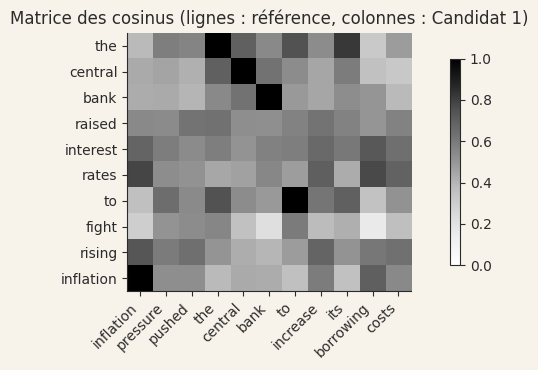

In [9]:
cand = candidates["Candidat 1 (paraphrase)"]
b = bertscore_greedy(reference, cand, kv)
print("Rappel : chaque mot de la RÉFÉRENCE -> mot du candidat le plus proche")
for i, w in enumerate(b["r"]):
    j = b["M"][i].argmax(); print(f"  {w:10s} -> {b['c'][j]:10s} cos = {b['M'][i, j]:.3f}")
print(f"R = moyenne des {len(b['r'])} valeurs = {b['R']:.3f}\n")
print("Précision : chaque mot du CANDIDAT -> mot de la référence le plus proche")
for j, w in enumerate(b["c"]):
    i = b["M"][:, j].argmax(); print(f"  {w:10s} -> {b['r'][i]:10s} cos = {b['M'][i, j]:.3f}")
print(f"P = moyenne des {len(b['c'])} valeurs = {b['P']:.3f}\n")
print(f"F1 = 2*{b['P']:.3f}*{b['R']:.3f} / ({b['P']:.3f}+{b['R']:.3f}) = {b['F1']:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
im = ax.imshow(b["M"], cmap="Greys", vmin=0, vmax=1)
ax.set_xticks(range(len(b["c"]))); ax.set_xticklabels(b["c"], rotation=45, ha="right")
ax.set_yticks(range(len(b["r"]))); ax.set_yticklabels(b["r"])
ax.set_title("Matrice des cosinus (lignes : référence, colonnes : Candidat 1)")
plt.colorbar(im, ax=ax, shrink=.8); plt.tight_layout(); plt.show()

In [10]:
rows = []
for name, cand in candidates.items():
    bs = bertscore_greedy(reference, cand, kv)
    rows.append({"Summary": name, "BERTScore-style P (GloVe)": bs["P"], "R (GloVe)": bs["R"], "F1 (GloVe)": bs["F1"]})
glove_df = pd.DataFrame(rows).set_index("Summary")

compare = rouge_df[["ROUGE-1 F1", "ROUGE-2 F1", "ROUGE-L F1"]].join(glove_df)
compare

,ROUGE-1 F1,ROUGE-2 F1,ROUGE-L F1,BERTScore-style P (GloVe),R (GloVe),F1 (GloVe)
Summary,,,,,,
Candidat 1 (paraphrase),0.476,0.211,0.381,0.841,0.846,0.844
Candidat 2 (sens erroné),0.800,0.667,0.800,0.940,0.950,0.945


**Optionnel : le vrai BERTScore** (embeddings contextuels de DistilBERT). Si le modèle ne peut pas être téléchargé, la cellule affiche un message et le notebook continue.

In [11]:
try:
    from bert_score import score as bert_score
    P, R, F = bert_score(list(candidates.values()), [reference] * len(candidates),
                         model_type="distilbert-base-uncased", num_layers=5, lang="en", verbose=False)
    real_df = pd.DataFrame({"P": P.numpy(), "R": R.numpy(), "F1": F.numpy()}, index=list(candidates.keys()))
    print("Vrai BERTScore (DistilBERT, embeddings contextuels, sans recalage) :")
    display(real_df)
except Exception as e:
    print("Modèle du vrai BERTScore indisponible ici :", repr(e)[:150])

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Vrai BERTScore (DistilBERT, embeddings contextuels, sans recalage) :


,P,R,F1
Candidat 1 (paraphrase),0.882,0.892,0.887
Candidat 2 (sens erroné),0.969,0.969,0.969


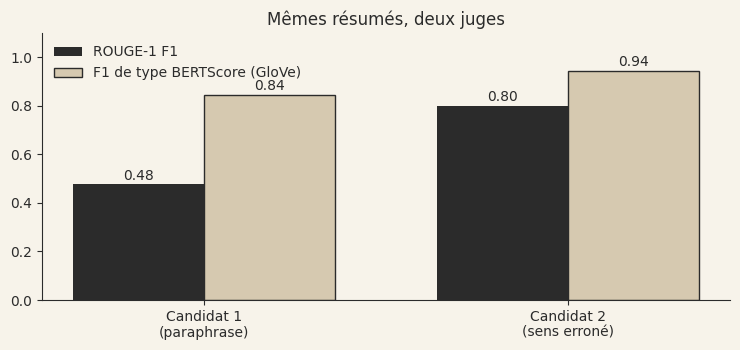

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.6)); x = np.arange(2); w = .36
ax.bar(x - w/2, compare["ROUGE-1 F1"], w, color=CHAR, label="ROUGE-1 F1")
ax.bar(x + w/2, compare["F1 (GloVe)"], w, color=SAND, edgecolor=CHAR, label="F1 de type BERTScore (GloVe)")
for i, (a, g) in enumerate(zip(compare["ROUGE-1 F1"], compare["F1 (GloVe)"])):
    ax.text(i - w/2, a + .02, f"{a:.2f}", ha="center"); ax.text(i + w/2, g + .02, f"{g:.2f}", ha="center")
ax.set_xticks(x); ax.set_xticklabels(["Candidat 1\n(paraphrase)", "Candidat 2\n(sens erroné)"]); ax.set_ylim(0, 1.1)
ax.set_title("Mêmes résumés, deux juges"); ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Interprétation : pourquoi les deux métriques divergent-elles ?**
- Pour la paraphrase (candidat 1), ROUGE-1 F1 vaut **0.48** mais le F1 par embeddings vaut **0.84**. ROUGE donne **zéro** à tout mot qui n'est pas une correspondance exacte ; le cosinus donne un crédit **partiel** (0.6 à 0.8) à ces mots, car deux mots quelconques ont une similarité positive (seuil de base élevé).
- Une partie de ce gain est donc un *effet de seuil de base*, pas de la compréhension : dans l'affichage pas à pas, *raised* est apparié à *the* (0.63), pas à *increase*. Les vecteurs GloVe statiques ne sont pas contextuels ; le vrai BERTScore utilise des embeddings contextuels et un recalage pour réduire ce problème.
- Les deux échelles ne sont pas comparables : 0.84 ne veut pas dire « 84 % correct ».
- Le candidat 2 (sens erroné) est noté **plus haut par les deux** métriques (ROUGE-1 0.80, F1 par embeddings 0.95) : 8 de ses 10 mots sont identiques (cosinus = 1) et les deux mots changés restent moyennement proches (*cut* ~ *raised* 0.65, *unemployment* ~ *inflation* 0.75). **Aucune métrique ne vérifie les faits.** C'est pourquoi le résumé automatique demande aussi des contrôles de factualité et un jugement humain.

## Section B. Question-réponse
**Question posée :** la réponse prédite est-elle la même que la réponse de référence ?
**Pourquoi deux métriques ?** un modèle peut avoir *raison mais formuler autrement* ; un score oui/non strict le cache.

**Normalisation d'abord** (comme le script officiel de SQuAD) : minuscules, suppression de la ponctuation, suppression des articles *a, an, the*. On évite ainsi de punir des différences qui ne changent pas la réponse.

| Métrique | Formule | Composants |
|---|---|---|
| Exact Match | EM = 1 si norm(pred) = norm(gold), sinon 0 | tout ou rien |
| Précision | P = communs / \|pred\| | communs = tokens partagés (comptes plafonnés) ; \|pred\| = tokens de la prédiction |
| Rappel | R = communs / \|gold\| | \|gold\| = tokens de la réponse de référence |
| F1 | F1 = 2PR / (P + R) | moyenne harmonique : élevée seulement si P et R sont élevés |

**Lecture d'un score :** EM = 1 signifie une réponse identique après normalisation. Un F1 entre 0 et 1 mesure un recouvrement partiel.
Précision basse + rappel haut = la réponse contient la bonne réponse plus des mots en trop. Précision haute + rappel bas = la réponse est juste mais incomplète.
**Avantage :** simple, peu coûteux, standard en QA extractif (SQuAD). **Limite :** purement lexical : *Vaswani et al.* et *Ashish Vaswani* ne partagent qu'un token alors qu'ils désignent la même personne.

In [13]:
def normalize(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)           # supprime la ponctuation
    text = re.sub(r"\b(a|an|the)\b", " ", text)        # supprime les articles
    return " ".join(text.split())

def exact_match(pred, gold):
    return float(normalize(pred) == normalize(gold))

def qa_scores(pred, gold):
    p_tok, g_tok = normalize(pred).split(), normalize(gold).split()
    common = sum((Counter(p_tok) & Counter(g_tok)).values())
    p, r, f = prf(common, len(p_tok), len(g_tok))
    return dict(p_tok=p_tok, g_tok=g_tok, common=common, EM=exact_match(pred, gold), P=p, R=r, F1=f)

qa_examples = [
    ("In which city is INPT located?",       "Rabat",                "Rabat"),
    ("In which city is INPT located?",       "in Rabat, Morocco",    "Rabat"),
    ("Who introduced the Transformer?",       "Vaswani et al.",       "Ashish Vaswani and colleagues"),
    ("When was BERT released?",               "2018",                 "October 2018"),
    ("What is the capital of Morocco?",       "Casablanca",           "Rabat"),
    ("Which mountains cross Morocco?",        "the Atlas Mountains",  "Atlas Mountains"),
]

**Calcul pas à pas pour la réponse partiellement correcte** (question 2 : bonne réponse, mots en trop).

In [14]:
q, pred, gold = qa_examples[1]
s = qa_scores(pred, gold)
print("Question   :", q); print("Prédiction :", pred, "| Référence :", gold)
print("1) normalisation  ->", s["p_tok"], "vs", s["g_tok"])
print(f"2) EM            = {s['EM']:.0f}   (les chaînes diffèrent après normalisation)")
print(f"3) tokens communs = {s['common']}")
print(f"4) Précision      = {s['common']}/{len(s['p_tok'])} = {s['P']:.3f}")
print(f"5) Rappel         = {s['common']}/{len(s['g_tok'])} = {s['R']:.3f}")
print(f"6) F1            = 2*{s['P']:.3f}*{s['R']:.3f} / ({s['P']:.3f}+{s['R']:.3f}) = {s['F1']:.3f}")

Question   : In which city is INPT located?
Prédiction : in Rabat, Morocco | Référence : Rabat
1) normalisation  -> ['in', 'rabat', 'morocco'] vs ['rabat']
2) EM            = 0   (les chaînes diffèrent après normalisation)
3) tokens communs = 1
4) Précision      = 1/3 = 0.333
5) Rappel         = 1/1 = 1.000
6) F1            = 2*0.333*1.000 / (0.333+1.000) = 0.500


,Question,Prediction,Reference,EM,Precision,Recall,F1
Q1,In which city is INPT located?,Rabat,Rabat,1.0,1.000,1.00,1.000
Q2,In which city is INPT located?,"in Rabat, Morocco",Rabat,0.0,0.333,1.00,0.500
Q3,Who introduced the Transformer?,Vaswani et al.,Ashish Vaswani and colleagues,0.0,0.333,0.25,0.286
Q4,When was BERT released?,2018,October 2018,0.0,1.000,0.50,0.667
Q5,What is the capital of Morocco?,Casablanca,Rabat,0.0,0.000,0.00,0.000
Q6,Which mountains cross Morocco?,the Atlas Mountains,Atlas Mountains,1.0,1.000,1.00,1.000


Niveau du jeu : EM = 0.333   F1 = 0.575   (moyenne simple sur les 6 questions)


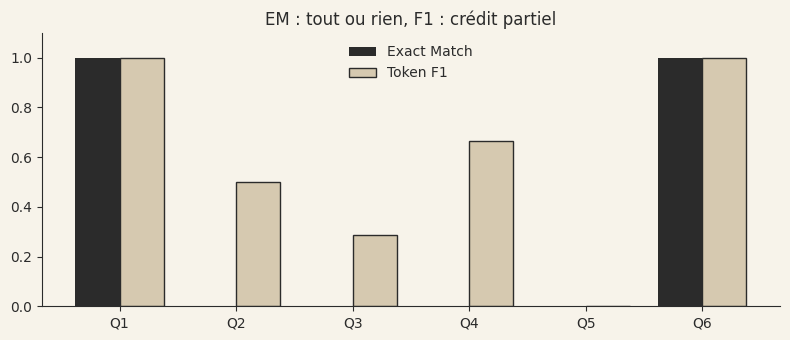

In [15]:
rows = []
for q, pred, gold in qa_examples:
    s = qa_scores(pred, gold)
    rows.append({"Question": q, "Prediction": pred, "Reference": gold, "EM": s["EM"], "Precision": s["P"], "Recall": s["R"], "F1": s["F1"]})
qa_df = pd.DataFrame(rows); qa_df.index = [f"Q{i+1}" for i in range(len(qa_df))]
display(qa_df)
print(f"Niveau du jeu : EM = {qa_df['EM'].mean():.3f}   F1 = {qa_df['F1'].mean():.3f}   (moyenne simple sur les {len(qa_df)} questions)")

x = np.arange(len(qa_df)); w = .38
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(x - w/2, qa_df["EM"], w, color=CHAR, label="Exact Match"); ax.bar(x + w/2, qa_df["F1"], w, color=SAND, edgecolor=CHAR, label="Token F1")
ax.set_xticks(x); ax.set_xticklabels(qa_df.index); ax.set_ylim(0, 1.1); ax.legend(frameon=False)
ax.set_title("EM : tout ou rien, F1 : crédit partiel"); plt.tight_layout(); plt.show()

**Interprétation.**
- Q1 et Q6 : EM = F1 = 1. Q6 montre la normalisation à l'œuvre : l'article *the* est supprimé, donc la réponse est jugée identique.
- Q2 (juste mais trop longue) : **EM = 0 mais F1 = 0.50**. Le rappel vaut 1 (le token attendu est présent), la précision 1/3 (deux mots en trop).
- Q4 (juste mais incomplète) : EM = 0, F1 = 0.67, avec le *schéma inverse* : précision 1.0, rappel 0.5.
- Q3 : F1 = 0.29 alors que la réponse est sémantiquement juste : la métrique est lexicale.
- Q5 (fausse) : EM = F1 = 0. Au niveau du jeu : **EM 0.33 contre F1 0.58**. L'écart mesure combien de réponses sont « presque justes ».

## Section C. Génération de texte
En génération ouverte, il n'y a **pas de référence unique** : les métriques avec référence (BLEU, ROUGE) ne sont pas universelles, elles n'ont de sens que si une référence proche existe (traduction, résumé).
On évalue donc des *propriétés* du texte. Trois textes :
- **A, répétitif :** la même phrase répétée.
- **B, divers et fluide :** onze mots différents formant une phrase sensée.
- **C, divers mais sans sens :** *exactement les mêmes onze mots que B, mélangés.*

In [16]:
texts = {
    "A (répétitif)":        "the model is good the model is good the model is good",
    "B (divers, fluide)":   "rain drummed on tin roofs while thunder rolled over quiet orchards",
    "C (divers, mélangé)": "quiet while orchards on rain rolled tin over drummed roofs thunder",
}
for k, v in texts.items():
    print(f"{k:24s} {len(v.split()):2d} mots | {v}")

A (répétitif)            12 mots | the model is good the model is good the model is good
B (divers, fluide)       11 mots | rain drummed on tin roofs while thunder rolled over quiet orchards
C (divers, mélangé)      11 mots | quiet while orchards on rain rolled tin over drummed roofs thunder


### C.1 Perplexité
| Élément | Description |
|---|---|
| Mesure | à quel point un modèle de langage (LM) est *surpris* par le texte : la prévisibilité moyenne de chaque mot sachant les précédents (fluidité selon ce LM). |
| Formule | **PPL(w₁…w<sub>N</sub>) = exp( −(1/N) Σ<sub>i</sub> ln P(wᵢ \| w<sub>i−1</sub>) )** = ( Π P )<sup>−1/N</sup> |
| Composants | `P(wᵢ \| w<sub>i−1</sub>)` : probabilité que le LM donne au vrai mot suivant. `ln` : le log transforme le produit en somme. `−(1/N) Σ` : log-probabilité négative moyenne par mot (l'entropie croisée). `exp` : revient à une échelle de « choix équiprobables ». |
| Intuition | PPL = le **nombre effectif de mots équiprobables** entre lesquels le modèle hésite à chaque étape. PPL = 1 : le modèle est certain. PPL = V (taille du vocabulaire) : il choisit au hasard. |
| Lecture d'un score | **plus bas = texte plus prévisible** pour ce LM. |
| Avantage | ne demande aucune référence ; marche sur tout texte et tout LM. |
| Limites | dépend du modèle, de son tokenizer et de ses données, donc **non comparable d'un modèle à l'autre** ; une valeur très basse peut signaler un texte ennuyeux ou répétitif ; ne dit rien de la vérité factuelle. |

**Exemple simplifié :** pour rendre le calcul visible, on utilise un petit **modèle bigramme** (chaque mot est prédit à partir du mot précédent), entraîné sur un mini-corpus avec un **lissage add-one** :
`P(w | préc) = (effectif(préc, w) + 1) / (effectif(préc) + V)`, où V est la taille du vocabulaire (le +1 évite les probabilités nulles pour les paires jamais vues).

In [17]:
corpus = ("the model is good . rain drummed on tin roofs while thunder rolled over quiet orchards . "
          "the model is fast . the thunder rolled over the hills .").split()
uni = Counter(corpus)
bi = Counter(zip(corpus[:-1], corpus[1:]))
V = len(uni) + 1                                  # +1 pour un symbole <unk> (mot inconnu)
print("mots d'entraînement :", len(corpus), "| taille du vocabulaire V =", V)

def bigram_prob(prev, w):
    w = w if w in uni else "<unk>"; prev = prev if prev in uni else "<unk>"
    return (bi[(prev, w)] + 1) / (uni[prev] + V)

def perplexity(sentence, verbose=False):
    toks = sentence.split()
    pairs = list(zip(toks[:-1], toks[1:]))
    probs = [bigram_prob(a, b) for a, b in pairs]
    logs = [math.log(p) for p in probs]
    N = len(pairs)
    if verbose:
        for (a, b), p, lg in zip(pairs, probs, logs):
            print(f"P({b:6s}| {a:6s}) = ({bi[(a, b)]}+1)/({uni[a]}+{V}) = {p:.4f}    ln P = {lg:.3f}")
        print(f"somme des ln P = {sum(logs):.3f}   N = {N}   moyenne de ln P = {sum(logs)/N:.3f}")
        print(f"PPL = exp(-moyenne) = exp({-sum(logs)/N:.3f}) = {math.exp(-sum(logs)/N):.3f}")
    return math.exp(-sum(logs) / N)

mots d'entraînement : 29 | taille du vocabulaire V = 19


**Calcul pas à pas sur une phrase courte** (3 prédictions).

In [18]:
ppl_demo = perplexity("the model is good", verbose=True)

P(model | the   ) = (2+1)/(4+19) = 0.1304    ln P = -2.037
P(is    | model ) = (2+1)/(2+19) = 0.1429    ln P = -1.946
P(good  | is    ) = (1+1)/(2+19) = 0.0952    ln P = -2.351
somme des ln P = -6.334   N = 3   moyenne de ln P = -2.111
PPL = exp(-moyenne) = exp(2.111) = 8.260


**Lecture :** PPL ≈ 8.26 signifie qu'à chaque étape ce modèle se comporte comme s'il choisissait parmi environ 8 mots équiprobables. Les paires jamais vues reçoivent de petites probabilités, ce qui augmente la valeur.
Voici maintenant les trois textes :

In [19]:
ppl_df = pd.DataFrame({"Bigram perplexity": {k: perplexity(v) for k, v in texts.items()}})
ppl_df

,Bigram perplexity
A (répétitif),9.701
"B (divers, fluide)",9.357
"C (divers, mélangé)",20.196


**Optionnel : perplexité de GPT-2** (un vrai LM léger, 124 millions de paramètres). Même formule : `exp(log-vraisemblance négative moyenne par token)`. Les valeurs diffèrent de celles du modèle jouet et ne doivent pas leur être comparées.

In [20]:
try:
    import torch
    from transformers import GPT2LMHeadModel, GPT2TokenizerFast
    tok = GPT2TokenizerFast.from_pretrained("gpt2"); lm = GPT2LMHeadModel.from_pretrained("gpt2").eval()
    def gpt2_ppl(text):
        enc = tok(text, return_tensors="pt")
        with torch.no_grad():
            nll = lm(**enc, labels=enc["input_ids"]).loss          # log-vraisemblance négative moyenne par token prédit
        return math.exp(nll.item())
    gpt2_df = pd.DataFrame({"GPT-2 perplexity": {k: gpt2_ppl(v) for k, v in texts.items()}})
    display(gpt2_df)
except Exception as e:
    print("GPT-2 indisponible ici :", repr(e)[:150])

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


,GPT-2 perplexity
A (répétitif),18.846
"B (divers, fluide)",407.352
"C (divers, mélangé)",2292.759


### C.2 Distinct-1 et Distinct-2
| Élément | Description |
|---|---|
| Mesure | la **diversité lexicale** : quelle part du texte est faite de mots *différents* (Distinct-1) ou de *paires de mots différentes* (Distinct-2). |
| Formule | **Distinct-n = (nombre de n-grammes uniques) / (nombre total de n-grammes)** |
| Composants | un n-gramme est un groupe de n mots consécutifs ; *unique* compte chaque n-gramme distinct une fois ; *total* compte chaque occurrence (avec répétitions). |
| Lecture d'un score | de presque 0 (les mêmes n-grammes répétés) à 1 (aucune répétition). |
| Pourquoi c'est nécessaire | les modèles fluides tombent souvent dans des boucles de répétition ; la perplexité ne les détecte pas. |
| Avantage | simple, sans référence, détecte la répétition. |
| Limites | **ignore le sens et la grammaire** : des mots au hasard obtiennent 1.0 ; dépend de la longueur du texte (un texte court paraît plus divers). |

In [21]:
def distinct_n(text, n):
    g = ngrams(text.split(), n)
    return len(set(g)) / len(g)

for name in ["A (répétitif)", "B (divers, fluide)"]:
    t = texts[name].split()
    print(f"=== {name} ===")
    for n in (1, 2):
        g = ngrams(t, n)
        print(f"Distinct-{n}: total de {n}-grammes = {len(g)}, uniques = {len(set(g))}  ->  {len(set(g))}/{len(g)} = {len(set(g))/len(g):.3f}")
    print("mots uniques :", sorted(set(t)), "\n")

=== A (répétitif) ===
Distinct-1: total de 1-grammes = 12, uniques = 4  ->  4/12 = 0.333
Distinct-2: total de 2-grammes = 11, uniques = 4  ->  4/11 = 0.364
mots uniques : ['good', 'is', 'model', 'the'] 

=== B (divers, fluide) ===
Distinct-1: total de 1-grammes = 11, uniques = 11  ->  11/11 = 1.000
Distinct-2: total de 2-grammes = 10, uniques = 10  ->  10/10 = 1.000
mots uniques : ['drummed', 'on', 'orchards', 'over', 'quiet', 'rain', 'rolled', 'roofs', 'thunder', 'tin', 'while'] 



## C.3 Les trois textes, les trois métriques : aucune ne suffit seule

,Distinct-1,Distinct-2,Bigram perplexity
A (répétitif),0.333,0.364,9.701
"B (divers, fluide)",1.000,1.000,9.357
"C (divers, mélangé)",1.000,1.000,20.196


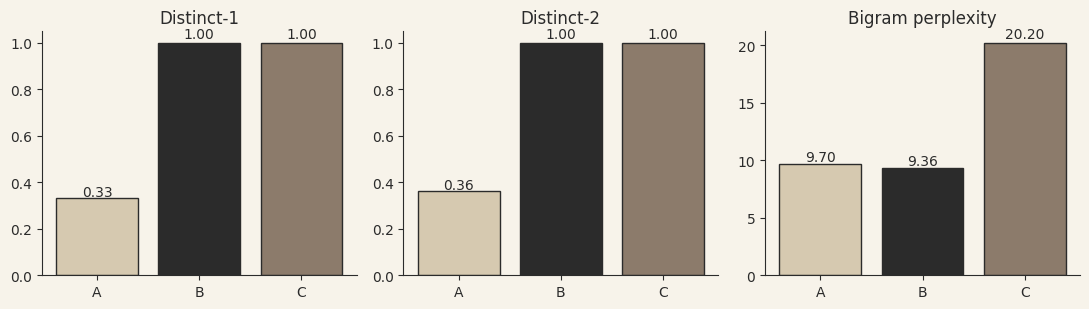

In [22]:
summary = pd.DataFrame({
    "Distinct-1": {k: distinct_n(v, 1) for k, v in texts.items()},
    "Distinct-2": {k: distinct_n(v, 2) for k, v in texts.items()},
    "Bigram perplexity": {k: perplexity(v) for k, v in texts.items()},
})
display(summary)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col in zip(axes, summary.columns):
    ax.bar(["A", "B", "C"], summary[col], color=[SAND, CHAR, TAUPE], edgecolor=CHAR)
    for i, v in enumerate(summary[col]): ax.text(i, v * 1.02, f"{v:.2f}", ha="center")
    ax.set_title(col)
plt.tight_layout(); plt.show()

**Interprétation.**
- **A contre B :** Distinct-1 passe de **1.00 à 0.33** et Distinct-2 de **1.00 à 0.36** quand le texte est répétitif : Distinct-n détecte la répétition. Mais la perplexité ne les sépare pas (A **9.70**, B **9.36**) : un texte répétitif est aussi prévisible qu'un texte fluide.
- **B contre C :** mêmes mots, donc **Distinct-1 et Distinct-2 sont identiques (1.00)**, pourtant C est du charabia. Seule la perplexité le révèle (**20.20** contre 9.36).
- **Une forte diversité ne veut pas dire une bonne qualité :** C a la diversité maximale et aucun sens. La diversité doit se lire *avec* la fluidité, la cohérence et la pertinence.
- Chaque métrique seule se trompe une fois ; ensemble, elles séparent les trois textes (A : peu divers ; B : divers et prévisible ; C : divers mais imprévisible).
- La perplexité vient ici d'un mini-corpus : elle montre le mécanisme, pas la qualité d'un vrai modèle.

### C.4 Évaluation humaine (approche complémentaire)
Les métriques automatiques ne jugent pas la cohérence, la factualité, l'utilité, le style. L'évaluation humaine comble ce manque :
- **Protocole :** plusieurs évaluateurs notent chaque texte sur une échelle (par exemple 1 à 5) pour la *fluidité, la cohérence, la pertinence, la factualité*, ou comparent deux sorties côte à côte (préférence par paires).
- **Score :** la note moyenne (MOS) par critère : `MOS = (1/K) Σ note_k` sur K évaluateurs.
- **Fiabilité :** on indique l'accord entre évaluateurs (par exemple le kappa de Cohen ou l'alpha de Krippendorff). **Le kappa de Cohen mesure l'accord entre évaluateurs, pas la qualité du texte généré lui-même.**
- **Limites :** lente, coûteuse, subjective, difficile à reproduire. Elle sert donc à *valider* les métriques automatiques, pas à les remplacer.

## Références
- Lin, C.-Y. (2004). *ROUGE: A Package for Automatic Evaluation of Summaries.* ACL Workshop on Text Summarization Branches Out.
- Zhang, T., Kishore, V., Wu, F., Weinberger, K. Q., Artzi, Y. (2020). *BERTScore: Evaluating Text Generation with BERT.* ICLR 2020. arXiv:1904.09675.
- Pennington, J., Socher, R., Manning, C. D. (2014). *GloVe: Global Vectors for Word Representation.* EMNLP 2014.
- Rajpurkar, P., Zhang, J., Lopyrev, K., Liang, P. (2016). *SQuAD: 100,000+ Questions for Machine Comprehension of Text.* EMNLP 2016. arXiv:1606.05250.
- Li, J., Galley, M., Brockett, C., Gao, J., Dolan, B. (2016). *A Diversity-Promoting Objective Function for Neural Conversation Models.* NAACL-HLT 2016 (Distinct-1/2).
- Jurafsky, D., Martin, J. H. *Speech and Language Processing* (3rd ed. draft), chapter on N-gram language models (perplexity).
- Radford, A. et al. (2019). *Language Models are Unsupervised Multitask Learners* (GPT-2). OpenAI.